# Oerlemans glacier-length and ELA figures

    Figure 1: length anomalies L' (Fig. 7.7-style) from the original dataset.
    Figure 2: ELA reconstruction E' (Fig. 7.8-style) from the original dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.interpolate import make_smoothing_spline, PchipInterpolator
from scipy.optimize import lsq_linear
 
from glacier_data import load_glacier_dataset
 
plt.rcParams.update({"figure.figsize": (5.6, 4.4)})
plt.style.use('seaborn-v0_8')

In [2]:
## Setup
YEARS = np.arange(1897, 2005)      # years plotted
LAM = 100                          # smoothing strength (larger = smoother)
C_B, TAU_B = -8.0, 5.02            # Briksdalsbreen: fixed sensitivity and response time
GAPS = ((1958, 1978),)             # years left out of the fit (E' is bridged by a straight line)
FIT_START_YEAR = 1910
ANCHOR_YEARS, ANCHOR_VALUE = (1900, 1920), -45   # Briksdalsbreen level in the plot

## 1. Load the original dataset

In [3]:
_, records = load_glacier_dataset()
 
old_lengths = records[["ID", "name", "year", "dL_m"]].copy()
old_lengths["year"] = pd.to_numeric(old_lengths["year"], errors="coerce")
old_lengths["dL_m"] = pd.to_numeric(old_lengths["dL_m"], errors="coerce")
old_lengths = old_lengths.dropna(subset=["ID", "year", "dL_m"])
old_lengths["year"] = old_lengths["year"].astype(int)
 
 
def glacier_id_from_name(name):
    hit = old_lengths.loc[
        old_lengths["name"].astype(str).str.contains(name, case=False, regex=False), "ID"
    ]
    if hit.empty:
        raise ValueError(f"No glacier matching {name!r} in records['name'].")
    return hit.iloc[0]
 
 
BRIKS_ID = glacier_id_from_name("Briksdals")
NIGARDS_ID = glacier_id_from_name("Nigardsbreen")
print("Briksdalsbreen ID:", BRIKS_ID, "| Nigardsbreen ID:", NIGARDS_ID)

Briksdalsbreen ID: 26 | Nigardsbreen ID: 119


### 2. Smooth, interpolate and plot $L'$ (Fig. 7.7-style)
`smooth_fit` returns a smoothing spline: call it with years for $L'$, and use
`.derivative()` for $dL'/dt$. 

Gaps in the record are bridged smoothly.

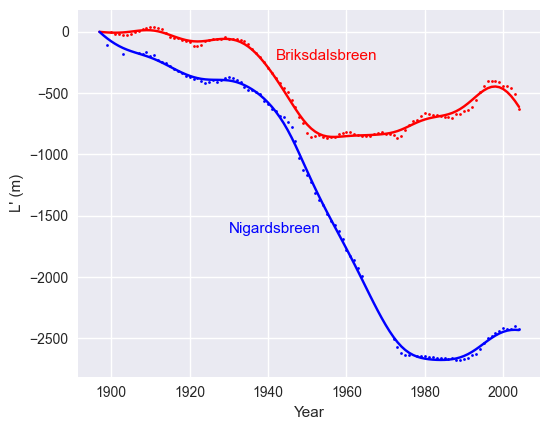

In [4]:
def smooth_fit(data, glacier_id, lam=LAM, first_year=1850, last_year=2010):
    g = (
        data.loc[
            (data["ID"] == glacier_id) & data["year"].between(first_year, last_year),
            ["year", "dL_m"],
        ]
        .groupby("year", as_index=False)["dL_m"].mean()
        .sort_values("year")
    )
    return make_smoothing_spline(g["year"].to_numpy(float), g["dL_m"].to_numpy(float), lam=lam)
 
 
fB = smooth_fit(old_lengths, BRIKS_ID, first_year=1869)
fN = smooth_fit(old_lengths, NIGARDS_ID, first_year=1675)
 
fig, ax = plt.subplots(figsize=(5.6, 4.4))
for gid, f, color in [
    (BRIKS_ID, fB, "red"),
    (NIGARDS_ID, fN, "blue"),
]:
    L0 = float(f(YEARS[0]))                      # same reference for curve and points
    obs = old_lengths[(old_lengths["ID"] == gid)
                      & old_lengths["year"].between(YEARS[0], YEARS[-1])]
    ax.plot(YEARS, f(YEARS) - L0, color=color)
    ax.plot(obs["year"], obs["dL_m"] - L0, ".", color=color, ms=4)

ax.tick_params(direction='in', top=True, right=True)
ax.text(1942, -230,  'Briksdalsbreen', color='red',  fontsize=11)
ax.text(1930, -1640, 'Nigardsbreen',  color='blue', fontsize=11)
ax.set_xlabel("Year")
ax.set_ylabel("L' (m)")
#ax.set_title("Recreation of Fig 7.7 with new data")
fig.tight_layout()
plt.show()

### 3. Fit $\tau_N$ and $c_N$, then plot $E'$ (Fig. 7.8-style)
$E' = \frac{L' + \tau * dL'/dt}{c}$

Briksdalsbreen uses the fixed $C_B$ and $\tau_B$;
$\tau_N$ and $c_N$ are found by bounded linear least squares so that the two $E'$ curves agree over the fit years.


In [5]:
def ela_curve(f, c, tau, years):
    return (f(years) + tau * f.derivative()(years)) / c
 
 
def fit_linear(fB, fN, years, mask, c_B=C_B, tau_B=TAU_B):
    def dm(x):
        x = x[mask]
        return x - x.mean()
 
    LB, dLB = fB(years), fB.derivative()(years)
    LN, dLN = fN(years), fN.derivative()(years)
 
    y = -dm((LB + tau_B * dLB) / c_B)
    A = np.column_stack([-dm(LN), -dm(dLN)])
    res = lsq_linear(A, y, bounds=([-np.inf, -np.inf], [-1e-6, 0.0]))
    v, w = res.x
    return {
        "tau_N": w / v,
        "c_N": 1 / v,
        "psi": float(np.sqrt(np.mean((A @ res.x - y) ** 2))),
        "success": res.success,
    }

Fit success: True
tau_N = 35.05 years
c_N   = -27.75
Psi   = 7.96 m


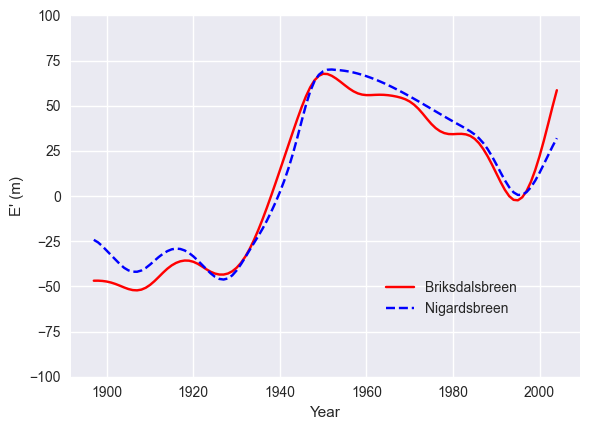

In [18]:
gap_mask = np.zeros(len(YEARS), dtype=bool)
for first, last in GAPS:
    gap_mask |= (YEARS >= first) & (YEARS <= last)
fit_mask = (YEARS >= FIT_START_YEAR) & ~gap_mask
 
fit = fit_linear(fB, fN, YEARS, fit_mask)
print(f"Fit success: {fit['success']}")
print(f"tau_N = {fit['tau_N']:.2f} years")
print(f"c_N   = {fit['c_N']:.2f}")
print(f"Psi   = {fit['psi']:.2f} m")
 
EB = ela_curve(fB, C_B, TAU_B, YEARS)
EN = ela_curve(fN, fit["c_N"], fit["tau_N"], YEARS)

# Level: anchor Briksdalsbreen, then align Nigardsbreen over the fit years.
anchor = (YEARS >= ANCHOR_YEARS[0]) & (YEARS <= ANCHOR_YEARS[1])
EB = EB - EB[anchor].mean() + ANCHOR_VALUE
EN = EN + (EB - EN)[fit_mask].mean()
 
# No data constrain E' in the excluded years: bridge Nigardsbreen with a straight line.
EN_plot = EN.copy()
EN_plot[gap_mask] = np.interp(YEARS[gap_mask], YEARS[~gap_mask], EN[~gap_mask])

# Smoothing with a PCHIP interpolator to avoid oscillations in the gap.
MARGIN = 3   # try 3: start the bridge 3 years before and end it 3 years after the gap
wide = gap_mask.copy()
for k in range(1, MARGIN + 1):
    wide |= np.roll(gap_mask, k) | np.roll(gap_mask, -k)

outside = ~wide & np.isfinite(EN)
bridge = PchipInterpolator(YEARS[outside], EN[outside])

EN_smooth = EN.copy()
EN_smooth[wide] = bridge(YEARS[wide])
 
fig, ax = plt.subplots(figsize=(6, 4.4))
ax.plot(YEARS, EB, "r-", label="Briksdalsbreen")
ax.plot(YEARS, EN_smooth, "b--", label="Nigardsbreen")
ax.set_ylim(-100, 100)
ax.set_xlabel("Year")
ax.set_ylabel("E' (m)")
#ax.set_title("Recreation of Fig 7.8 with new data")
ax.legend(frameon=False, bbox_to_anchor=(0.9, 0.3))
fig.tight_layout()
plt.show()
